Load Packages

In [3]:
# Import packages
import tensorflow as tf
import keras
import numpy as np
import pandas as pd
import PIL
import pathlib
import os
from keras.models import *
from keras.layers import *
from keras.optimizers import *
from keras.losses import *
import requests

import pyunpack
import matplotlib.pyplot as plt
from keras import backend as K
from keras.callbacks import ModelCheckpoint
import sys


from rarfile import RarFile
#import segmentation_models as sm
import segmentation_models_pytorch as sm

from keras_segmentation.models import segnet
from keras.applications import vgg16
from sklearn.metrics import *
import rioxarray as rxr
from tensorflow.keras.preprocessing.image import ImageDataGenerator

ModuleNotFoundError: No module named 'pyunpack'

In [4]:
pip install tensorflow==2.10.0

ERROR: Could not find a version that satisfies the requirement tensorflow==2.10.0 (from versions: 2.12.0rc0, 2.12.0rc1, 2.12.0, 2.12.1, 2.13.0rc0, 2.13.0rc1, 2.13.0rc2, 2.13.0, 2.13.1, 2.14.0rc0, 2.14.0rc1, 2.14.0, 2.14.1, 2.15.0rc0, 2.15.0rc1, 2.15.0, 2.15.0.post1, 2.15.1, 2.16.0rc0, 2.16.1, 2.16.2, 2.17.0rc0, 2.17.0rc1, 2.17.0, 2.17.1, 2.18.0rc0, 2.18.0rc1, 2.18.0rc2, 2.18.0, 2.18.1, 2.19.0rc0, 2.19.0)
ERROR: No matching distribution found for tensorflow==2.10.0


In [ ]:
pip install pyunpack


Note: you may need to restart the kernel to use updated packages.


In [ ]:
pip install RarFile

Note: you may need to restart the kernel to use updated packages.


In [ ]:
pip install keras==2.10

Note: you may need to restart the kernel to use updated packages.


In [ ]:
pip install segmentation_models

Note: you may need to restart the kernel to use updated packages.


In [ ]:
pip install --upgrade keras_segmentation


In [ ]:
pip install keras_segmentation --user


Note: you may need to restart the kernel to use updated packages.


In [ ]:
pip install rioxarray --user


  Using cached numpy-1.26.4-cp39-cp39-win_amd64.whl (15.8 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.22.4
    Uninstalling numpy-1.22.4:
      Successfully uninstalled numpy-1.22.4
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'C:\\Users\\20101537\\AppData\\Roaming\\Python\\Python39\\site-packages\\~-mpy\\.libs\\libopenblas.EL2C6PLE4ZYW3ECEVIV3OXXGRN2NRFM2.gfortran-win_amd64.dll'
Check the permissions.



In [ ]:
base_dir2 = 'E:/dataset/ATLANTIC FOREST/ATLANTIC_FOREST/'

Functions

In [ ]:
'''
  Returns an image plot of mask prediction
'''

def reconstruct_image(model, image, rounded=False):

  # Find model prediction
  reconstruction = model.predict(image).reshape(image.shape[1], image.shape[2])
  # Standardise between 0-1
  reconstruction = reconstruction/np.max(reconstruction)

  # Round to 0-1, binary pixel-by-pixel classification
  if rounded:
    reconstruction = np.round(reconstruction)

  # Plot reconstructed mask (prediction)
  plt.imshow(reconstruction)

In [ ]:
'''
  Returns array of mask prediction, given model and image
'''
def reconstruct_array(model, image, rounded=False):

  # Find model prediction
  reconstruction = model.predict(image).reshape(image.shape[1], image.shape[2])

  if rounded:
    reconstruction = np.round(reconstruction)

  return reconstruction # Returns array

In [ ]:
'''
  Metric functions for evaluation
'''

def score_eval(model, image, mask): # Gives score of mask vs prediction
  if type(image) != list:
    reconstruction = model.predict(image).reshape(mask.shape[1], mask.shape[2])
    reconstruction = np.round(reconstruction).flatten()

    return accuracy_score(mask.flatten(), reconstruction)

  else: # If a list of images input, find accuracy for each
    scores = []
    for i in range(len(image)):
      reconstruction = model.predict(image[i].reshape(1, 512, 512, 3))
      reconstruction = np.round(reconstruction).flatten()

      scores.append(accuracy_score(mask[i].flatten(), reconstruction))

    return scores

def score_eval2(model, image, mask): # Gives score of mask vs prediction
  if type(image) != list:
    reconstruction = model.predict(image).reshape(mask.shape[1], mask.shape[2])
    reconstruction = np.round(reconstruction).flatten()

    return accuracy_score(mask.flatten(), reconstruction)

  else: # If a list of images input, find accuracy for each
    scores = []
    for i in range(len(image)):
      reconstruction = model.predict(image[i].reshape(1, 512, 512, 4))
      reconstruction = np.round(reconstruction).flatten()

      scores.append(accuracy_score(mask[i].flatten(), reconstruction))

    return scores

def recall_eval(model, image, mask): # Find recall score
  if type(image) != list:
    reconstruction = model.predict(image).reshape(mask.shape[1], mask.shape[2])
    reconstruction = np.round(reconstruction).flatten()

    return recall_score(mask.flatten(), reconstruction, average='weighted')

  else: # If a list of images input, find accuracy for each
    recall = []
    for i in range(len(image)):
        reconstruction = model.predict(image[i]).reshape(mask[i].shape[1], mask[i].shape[2])
        reconstruction = np.round(reconstruction).flatten()

        recall.append(recall_score(mask[i].flatten(), reconstruction, average='weighted'))

    return recall

def precision_eval(model, image, mask): # Find precision score
  if type(image) != list:
    reconstruction = model.predict(image).reshape(mask.shape[1], mask.shape[2])
    reconstruction = np.round(reconstruction).flatten()

    return precision_score(mask.flatten(), reconstruction, average='weighted')

  else: # If a list of images input, find accuracy for each
    precision = []
    for i in range(len(image)):
        reconstruction = model.predict(image[i]).reshape(mask[i].shape[1], mask[i].shape[2])
        reconstruction = np.round(reconstruction).flatten()

        precision.append(precision_score(mask[i].flatten(), reconstruction, average='weighted'))

    return precision

def f1_score_eval(model, image, mask): # Find F1-score
    prec = np.mean(precision_eval(model, image, mask))
    rec = np.mean(recall_eval(model, image, mask))

    if prec + rec == 0:
        return 0

    return 2 * (prec * rec) / (prec + rec)

def f1_score_eval_basic(precision, recall):
    prec = np.mean(precision)
    rec = np.mean(recall)

    if prec + rec == 0:
        return 0

    return 2 * (prec * rec) / (prec + rec)

def produce_mask(image): # Outputs rounded image (binary)
  return np.round(image)

Ingest and Process 4-band Datasets

In [ ]:
# Ingest images and normalise

## Training images
training_images_list2 = os.listdir(r"{}Training/image/".format(base_dir2))[0:250]
training_masks_list2 = []
training_images2 = []
for n in training_images_list2:
  training_masks_list2.append(n)
  a = (np.array(rxr.open_rasterio(r"{}Training/image/{}".format(base_dir2,n))))
  a = (a-np.min(a)) / (np.max(a)-np.min(a))
  training_images2.append(a)

## Training masks
training_masks2 = []
for n in training_masks_list2:
  a = (np.array(rxr.open_rasterio(r"{}Training/label/{}".format(base_dir2,n))))
  training_masks2.append(a)

## Test images
test_images_list2 = os.listdir(r"{}Test/image/".format(base_dir2))
test_masks_list2 = []
test_images2 = []
for n in test_images_list2:
  test_masks_list2.append(n)
  a = (np.array(rxr.open_rasterio(r"{}Test/image/{}".format(base_dir2,n))))
  a = (a-np.min(a)) / (np.max(a)-np.min(a))
  test_images2.append(a)

## Test masks
test_masks2 = []
for n in test_masks_list2:
  a = (np.array(rxr.open_rasterio(r"{}Test/mask/{}".format(base_dir2,n))))
  test_masks2.append(a)

## Validation images
validation_images_list2 = os.listdir(r"{}Validation/images/".format(base_dir2))
validation_masks_list2 = []
validation_images2 = []
for n in validation_images_list2:
  validation_masks_list2.append(n)
  a = (np.array(rxr.open_rasterio(r"{}Validation/images/{}".format(base_dir2,n))))
  a = (a-np.min(a)) / (np.max(a)-np.min(a))
  validation_images2.append(a)

## Validation masks
validation_masks2 = []
for n in validation_masks_list2:
  a = (np.array(rxr.open_rasterio(r"{}Validation/masks/{}".format(base_dir2,n))))
  validation_masks2.append(a)

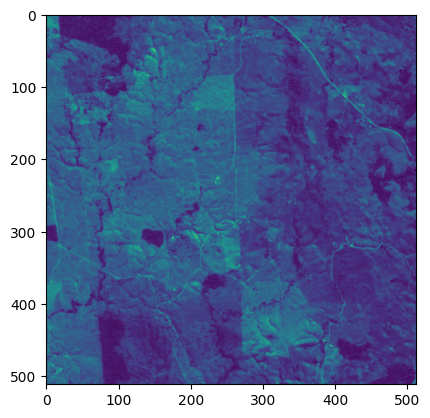

In [ ]:
# Show example train image
plt.imshow((np.array(rxr.open_rasterio(r"{}Training/image/{}".format(base_dir2,training_images_list2[2])))[0,:,:]))

In [ ]:
# Pre-process data, reshaping and transposing
for i in range(len(training_images2)):
  training_images2[i] = training_images2[i].astype('float32')
  training_images2[i] = training_images2[i].T

for i in range(len(training_masks2)):
  training_masks2[i] = training_masks2[i].reshape(1,512,512,1)
  training_masks2[i] = training_masks2[i].T

for i in range(len(validation_images2)):
  validation_images2[i] = validation_images2[i].astype('float32')
  validation_images2[i] = validation_images2[i].T

for i in range(len(validation_masks2)):
  validation_masks2[i] = validation_masks2[i].reshape(1,512,512,1)
  validation_masks2[i] = validation_masks2[i].T

for i in range(len(test_images2)):
  test_images2[i] = test_images2[i].astype('float32')
  test_images2[i] = test_images2[i].T

for i in range(len(test_masks2)):
  test_masks2[i] = test_masks2[i].reshape(1,512,512,1)
  test_masks2[i] = test_masks2[i].T

for i in range(len(training_images2)):
  training_images2[i] = training_images2[i].reshape(-1,512,512,4)

for i in range(len(validation_images2)):
  validation_images2[i] = validation_images2[i].reshape(-1,512,512,4)

for i in range(len(test_images2)):
  test_images2[i] = test_images2[i].reshape(-1,512,512,4)

In [ ]:
# Create TensorFlow datasets for training and validation sets
train_df_4band_amazon = tf.data.Dataset.from_tensor_slices((training_images2[0:250], training_masks2[0:250]))
validation_df_4band_amazon = tf.data.Dataset.from_tensor_slices((validation_images2, validation_masks2))

Models

In [ ]:
'''
  Convolutional block with two conv layers and two activation layers

  15/5/24 ---------atlantic 24/4/25
'''
from keras.layers import BatchNormalization

def convBlock(input, filters, kernel, kernel_init='he_normal', act='relu', transpose=False):
  if transpose == False:
    #conv = ZeroPadding2D((1,1))(input)
    conv = Conv2D(filters, kernel, padding = 'same', kernel_initializer = kernel_init)(input)
  else:
    #conv = ZeroPadding2D((1,1))(input)
    conv = Conv2DTranspose(filters, kernel, padding = 'same', kernel_initializer = kernel_init)(input)

  conv = BatchNormalization()(conv)
  conv = Activation(act)(conv)
  return conv

def convBlock2(input, filters, kernel, kernel_init='he_normal', act='relu', transpose=False):
  if transpose == False:
    conv = Conv2D(filters, kernel, padding = 'same', kernel_initializer = kernel_init)(input)
    conv = BatchNormalization()(conv)
    conv = Activation(act)(conv)
    conv = Conv2D(filters, kernel, padding = 'same', kernel_initializer = kernel_init)(conv)
    conv = BatchNormalization()(conv)
    conv = Activation(act)(conv)
  else:
    conv = Conv2DTranspose(filters, kernel, padding = 'same', kernel_initializer = kernel_init)(input)
    conv = BatchNormalization()(conv)
    conv = Activation(act)(conv)
    conv = Conv2DTranspose(filters, kernel, padding = 'same', kernel_initializer = kernel_init)(conv)
    conv = BatchNormalization()(conv)
    conv = Activation(act)(conv)

  return conv

'''
  Attention block/mechanism
'''
def attention_block(x, gating, inter_shape, drop_rate=0.25):

    # Find shape of inputs
    shape_x = K.int_shape(x)
    shape_g = K.int_shape(gating)

    ## Process x vector and gating signal
    # x vector input and processing
    theta_x = Conv2D(inter_shape, kernel_size = 1, strides = 1, padding='same', kernel_initializer='he_normal', activation=None)(x)
    theta_x = MaxPooling2D((2,2))(theta_x)
    shape_theta_x = K.int_shape(theta_x)

    # gating signal ""
    phi_g = Conv2D(inter_shape, kernel_size = 1, strides = 1, padding='same', kernel_initializer='he_normal', activation=None)(gating)
    shape_phi_g = K.int_shape(phi_g)

    # Add components
    concat_xg = add([phi_g, theta_x])
    act_xg = Activation('relu')(concat_xg)

    # Apply convolution
    psi = Conv2D(1, kernel_size = 1, strides = 1, padding='same', kernel_initializer='he_normal', activation=None)(act_xg)

    # Apply sigmoid activation
    sigmoid_xg = Activation('sigmoid')(psi)
    shape_sigmoid = K.int_shape(sigmoid_xg)

    # UpSample and resample to correct size
    upsample_psi = UpSampling2D(interpolation='bilinear', size=(shape_x[1] // shape_sigmoid[1], shape_x[2] // shape_sigmoid[2]))(sigmoid_xg)
    upsample_psi = tf.broadcast_to(upsample_psi, shape=shape_x)
    y = multiply([upsample_psi, x])

    return y


'''
  Attention U-Net model
'''

def UNetAM(trained_weights = None, input_size = (512,512,3), drop_rate = 0.25, lr=0.0001, filter_base=16):

  ## Can add pretrained weights by specifying 'trained_weights'

  # Input layer
  inputs = Input(input_size, batch_size=1)

  ## Contraction phase
  conv = convBlock2(inputs, filter_base, 3)
  #conv0 = Dropout(drop_rate)(conv0)

  conv0 = MaxPooling2D(pool_size=(2, 2))(conv)
  conv0 = convBlock2(conv0, 2 * filter_base, 3)

  pool0 = MaxPooling2D(pool_size=(2, 2))(conv0)
  conv1 = convBlock2(pool0, 4 * filter_base, 3)
  #conv1 = Dropout(drop_rate)(conv1)

  pool1 = MaxPooling2D(pool_size=(2, 2))(conv1)
  conv2 = convBlock2(pool1, 8 * filter_base, 3)
  #conv2 = Dropout(drop_rate)(conv2)

  pool2 = MaxPooling2D(pool_size=(2, 2))(conv2)
  conv3 = convBlock2(pool2, 16 * filter_base, 3)
  #conv3 = Dropout(drop_rate)(conv3)

  ## Expansion phase
  up4 = (Conv2DTranspose(8 * filter_base, kernel_size=2, strides=2, kernel_initializer='he_normal')(conv3))
  up4 = BatchNormalization()(up4)
  merge4 = attention_block(conv2, conv3, 8 * filter_base, drop_rate) # Attention gate
  conv4 = concatenate([up4, merge4])
  conv4 = convBlock2(conv4, 8 * filter_base, 3)

  up5 = (Conv2DTranspose(4 * filter_base, kernel_size=2, strides=2, kernel_initializer='he_normal')(conv4))
  up5 = BatchNormalization()(up5)
  merge5 = attention_block(conv1, conv4, 4 * filter_base, drop_rate) # Attention gate
  conv5 = concatenate([up5, merge5])
  conv5 = convBlock2(conv5, 4 * filter_base, 3)

  up6 = (Conv2DTranspose(2 * filter_base, kernel_size=2, strides=2, kernel_initializer='he_normal')(conv5))
  up6 = BatchNormalization()(up6)
  merge6 = attention_block(conv0, conv5, 2 * filter_base, drop_rate) # Attention gate
  conv6 = concatenate([up6, merge6])
  conv6 = convBlock2(conv6, 2 * filter_base, 3)

  up7 = (Conv2DTranspose(1 * filter_base, kernel_size=2, strides=2, kernel_initializer='he_normal')(conv6))
  up7 = BatchNormalization()(up7)
  merge7 = attention_block(conv, conv6, 1 * filter_base, drop_rate) # Attention gate
  conv7 = concatenate([up7, merge7])
  conv7 = concatenate([up7, conv])
  conv7 = convBlock2(conv7, 1 * filter_base, 3)

  ## Output layer
  out = convBlock(conv7, 1, 1, act='sigmoid')

  model = Model(inputs, out)

  model.compile(optimizer = adam_v2.Adam(learning_rate = lr), loss = binary_crossentropy, metrics = ['accuracy', 'mse'])

  if trained_weights != None:
    model.load_weights(trained_weights)

  return model

In [ ]:
'''
  Convolutional block with two conv layers and two activation layers

  14/5/24----------DO NOT USE
'''
from keras import regularizers

def convBlock(input, filters, kernel, kernel_init='he_normal', act='relu', transpose=False, drop_rate=0.25):
  if transpose == False:
    #conv = ZeroPadding2D((1,1))(input)
    conv = Conv2D(filters, kernel, padding = 'same', kernel_initializer = kernel_init, kernel_regularizer=regularizers.l2(0.001))(input)
  else:
    #conv = ZeroPadding2D((1,1))(input)
    conv = Conv2DTranspose(filters, kernel, padding = 'same', kernel_initializer = kernel_init, kernel_regularizer=regularizers.l2(0.001))(input)

  conv = Activation(act)(conv)
  conv = Dropout(drop_rate)(conv)
  return conv

def convBlock2(input, filters, kernel, kernel_init='he_normal', act='relu', transpose=False, drop_rate=0.25, kernel_regularizer=None):
  if transpose == False:
    conv = Conv2D(filters, kernel, padding = 'same', kernel_initializer = kernel_init, kernel_regularizer=kernel_regularizer)(input)
    conv = Activation(act)(conv)
    conv = Conv2D(filters, kernel, padding = 'same', kernel_initializer = kernel_init, kernel_regularizer=kernel_regularizer)(conv)
    conv = Activation(act)(conv)
  else:
    conv = Conv2DTranspose(filters, kernel, padding = 'same', kernel_initializer = kernel_init, kernel_regularizer=kernel_regularizer)(input)
    conv = Activation(act)(conv)
    conv = Conv2DTranspose(filters, kernel, padding = 'same', kernel_initializer = kernel_init, kernel_regularizer=kernel_regularizer)(conv)
    conv = Activation(act)(conv)

  conv = Dropout(drop_rate)(conv)
  return conv

'''
  Attention block/mechanism
'''
def attention_block(x, gating, inter_shape, drop_rate=0.25):

    # Find shape of inputs
    shape_x = K.int_shape(x)
    shape_g = K.int_shape(gating)

    ## Process x vector and gating signal
    # x vector input and processing
    theta_x = Conv2D(inter_shape, kernel_size = 1, strides = 1, padding='same', kernel_initializer='he_normal', activation=None)(x)
    theta_x = MaxPooling2D((2,2))(theta_x)
    shape_theta_x = K.int_shape(theta_x)

    # gating signal ""
    phi_g = Conv2D(inter_shape, kernel_size = 1, strides = 1, padding='same', kernel_initializer='he_normal', activation=None)(gating)
    shape_phi_g = K.int_shape(phi_g)

    # Add components
    concat_xg = add([phi_g, theta_x])
    act_xg = Activation('relu')(concat_xg)

    # Apply convolution
    psi = Conv2D(1, kernel_size = 1, strides = 1, padding='same', kernel_initializer='he_normal', activation=None)(act_xg)

    # Apply sigmoid activation
    sigmoid_xg = Activation('sigmoid')(psi)
    shape_sigmoid = K.int_shape(sigmoid_xg)

    # UpSample and resample to correct size
    upsample_psi = UpSampling2D(interpolation='bilinear', size=(shape_x[1] // shape_sigmoid[1], shape_x[2] // shape_sigmoid[2]))(sigmoid_xg)
    upsample_psi = tf.broadcast_to(upsample_psi, shape=shape_x)
    y = multiply([upsample_psi, x])

    return y


'''
  Attention U-Net model
'''

def UNetAM(trained_weights = None, input_size = (512,512,3), drop_rate = 0.25, lr=0.0001, filter_base=16,  reg='l1'):

  ## Can add pretrained weights by specifying 'trained_weights'

  # Input layer
  inputs = Input(input_size, batch_size=1)

  ## Contraction phase
  conv = convBlock2(inputs, filter_base, 3, kernel_init='he_normal', kernel_regularizer=regularizers.l2(0.0001))
  #conv0 = Dropout(drop_rate)(conv0)

  conv0 = MaxPooling2D(pool_size=(2, 2))(conv)
  conv0 = convBlock2(conv0, 2 * filter_base, 3, kernel_init='he_normal', kernel_regularizer=regularizers.l2(0.0001))

  pool0 = MaxPooling2D(pool_size=(2, 2))(conv0)
  conv1 = convBlock2(pool0, 4 * filter_base, 3, kernel_init='he_normal', kernel_regularizer=regularizers.l2(0.0001))
  #conv1 = Dropout(drop_rate)(conv1)

  pool1 = MaxPooling2D(pool_size=(2, 2))(conv1)
  conv2 = convBlock2(pool1, 8 * filter_base, 3, kernel_init='he_normal', kernel_regularizer=regularizers.l2(0.0001))
  #conv2 = Dropout(drop_rate)(conv2)

  pool2 = MaxPooling2D(pool_size=(2, 2))(conv2)
  conv3 = convBlock2(pool2, 16 * filter_base, 3, kernel_init='he_normal', kernel_regularizer=regularizers.l2(0.0001))
  #conv3 = Dropout(drop_rate)(conv3)

  ## Expansion phase
  up4 = (Conv2DTranspose(8 * filter_base, kernel_size=2, strides=2, kernel_initializer='he_normal')(conv3))
  merge4 = attention_block(conv2, conv3, 8 * filter_base, drop_rate) # Attention gate
  conv4 = concatenate([up4, merge4])
  conv4 = convBlock2(conv4, 8 * filter_base, 3, kernel_init='he_normal', kernel_regularizer=regularizers.l2(0.0001))

  up5 = (Conv2DTranspose(4 * filter_base, kernel_size=2, strides=2, kernel_initializer='he_normal')(conv4))
  merge5 = attention_block(conv1, conv4, 4 * filter_base, drop_rate) # Attention gate
  conv5 = concatenate([up5, merge5])
  conv5 = convBlock2(conv5, 4 * filter_base, 3, kernel_init='he_normal', kernel_regularizer=regularizers.l2(0.0001))

  up6 = (Conv2DTranspose(2 * filter_base, kernel_size=2, strides=2, kernel_initializer='he_normal')(conv5))
  merge6 = attention_block(conv0, conv5, 2 * filter_base, drop_rate) # Attention gate
  conv6 = concatenate([up6, merge6])
  conv6 = convBlock2(conv6, 2 * filter_base, 3, kernel_init='he_normal', kernel_regularizer=regularizers.l2(0.0001))

  up7 = (Conv2DTranspose(1 * filter_base, kernel_size=2, strides=2, kernel_initializer='he_normal')(conv6))
  merge7 = attention_block(conv, conv6, 1 * filter_base, drop_rate) # Attention gate
  conv7 = concatenate([up7, merge7])
  conv7 = concatenate([up7, conv])
  conv7 = convBlock2(conv7, 1 * filter_base, 3, kernel_init='he_normal', kernel_regularizer=regularizers.l2(0.0001))

  ## Output layer
  out = convBlock(conv7, 1, 1, act='sigmoid')

  model = Model(inputs, out)

  model.compile(optimizer = adam_v2.Adam(learning_rate = lr), loss = binary_crossentropy, metrics = ['accuracy', 'mse'])

  if trained_weights != None:
    model.load_weights(trained_weights)

  return model

In [ ]:
# Print model layers and number of parameters
UNetAM().summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(1, 512, 512, 3)]   0           []                               
                                                                                                  
 conv2d (Conv2D)                (1, 512, 512, 16)    448         ['input_1[0][0]']                
                                                                                                  
 batch_normalization (BatchNorm  (1, 512, 512, 16)   64          ['conv2d[0][0]']                 
 alization)                                                                                       
                                                                                                  
 activation (Activation)        (1, 512, 512, 16)    0           ['batch_normalization[0][0]']

Train on 4-band Atlantic data

In [ ]:
# Train U-Net with generator
model_attention_unet_4band = UNetAM(input_size=(512,512,4),  lr=0.0005, filter_base=16)

import time
start_time = time.time()

save_model_4band_attention = ModelCheckpoint('unet-attention-4d.hdf5', monitor='val_accuracy',verbose=1, save_best_only=True)
model_attention_unet_4band.fit(train_df_4band_amazon, epochs = 10, validation_data = validation_df_4band_amazon, callbacks=[save_model_4band_attention])

end_time = time.time()

total_time = end_time - start_time
print("Total training time (sec):", total_time)

Epoch 1/10
250/250 [==============================] - ETA: 0s - loss: 0.4436 - accuracy: 0.8622 - mse: 0.1346
Epoch 1: val_accuracy improved from -inf to 0.86625, saving model to unet-attention-4d.hdf5
250/250 [==============================] - 232s 916ms/step - loss: 0.4436 - accuracy: 0.8622 - mse: 0.1346 - val_loss: 0.4624 - val_accuracy: 0.8662 - val_mse: 0.1413
Epoch 2/10
250/250 [==============================] - ETA: 0s - loss: 0.3992 - accuracy: 0.8937 - mse: 0.1156
Epoch 2: val_accuracy did not improve from 0.86625
250/250 [==============================] - 235s 941ms/step - loss: 0.3992 - accuracy: 0.8937 - mse: 0.1156 - val_loss: 0.4165 - val_accuracy: 0.8537 - val_mse: 0.1238
Epoch 3/10
250/250 [==============================] - ETA: 0s - loss: 0.3695 - accuracy: 0.9096 - mse: 0.1035
Epoch 3: val_accuracy did not improve from 0.86625
250/250 [==============================] - 230s 921ms/step - loss: 0.3695 - accuracy: 0.9096 - mse: 0.1035 - val_loss: 0.4115 - val_accuracy: 

In [ ]:
# Save model history
np.save('unet-attention-4d-history.npy',model_attention_unet_4band.history.history)

Import Models and Compute Metrics

In [ ]:
# Load 4-dim models and history stats
attention_unet_4d=  UNetAM(input_size=(512,512,4),  lr=0.0005, filter_base=16)
attention_unet_4d.load_weights('unet-attention-4d.hdf5')

attention_unet_4d_history = np.load('unet-attention-4d-history.npy', allow_pickle='TRUE').item()

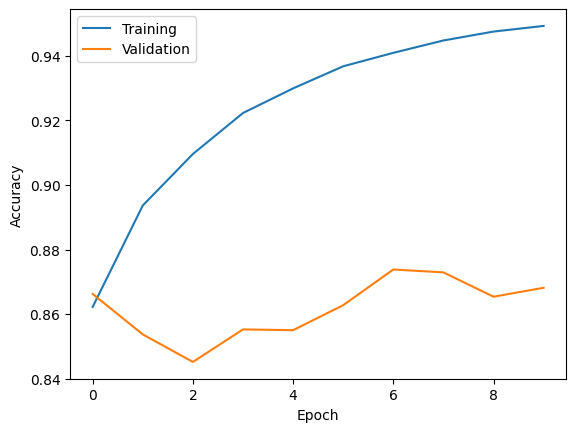

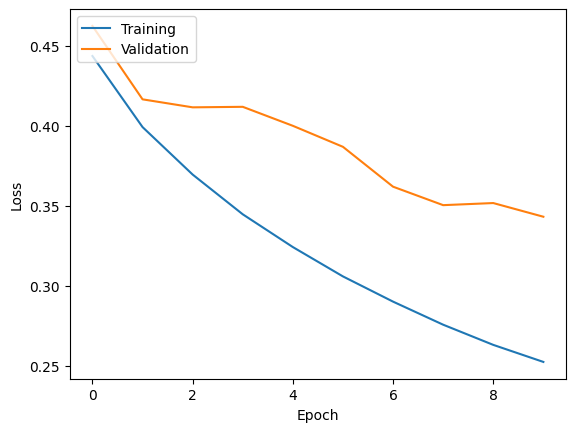

In [ ]:
# Plot accuracy and loss for Attention U-Net

## Accuracy
plt.plot(attention_unet_4d_history['accuracy'])
plt.plot(attention_unet_4d_history['val_accuracy'])
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Training', 'Validation'], loc='upper left')
plt.show()

## Loss
plt.plot(attention_unet_4d_history['loss'])
plt.plot(attention_unet_4d_history['val_loss'])
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Training', 'Validation'], loc='upper left')

In [ ]:
# Scores of each model
attention_unet_4d_score = (score_eval2(attention_unet_4d, validation_images2, validation_masks2))

# Precision and recall of each model
attention_unet_4d_precision = (precision_eval(attention_unet_4d, validation_images2, validation_masks2))
attention_unet_4d_recall = (recall_eval(attention_unet_4d, validation_images2, validation_masks2))

# F1-scores of each model
attention_unet_4d_f1_score = (f1_score_eval_basic(attention_unet_4d_precision, attention_unet_4d_recall))

# Print score eval results for each model
print('U-NetAm accuracy: ', np.mean(attention_unet_4d_score), np.std(attention_unet_4d_score))

# Print precision eval results for each model
print('U-NetAm precision: ', np.mean(attention_unet_4d_precision), np.std(attention_unet_4d_precision))

# Print recall eval results for each model
print('U-NetAm recall: ', np.mean(attention_unet_4d_recall), np.std(attention_unet_4d_recall))

# Print f1-score eval results for each model
print('U-NetAm F1-score: ', np.mean(attention_unet_4d_f1_score))

1/1 [==============================] - 0s 125ms/step
U-NetAm accuracy:  0.8738177871704101 0.1142405617410149
U-NetAm precision:  0.9232833071994322 0.05320700237831101
U-NetAm recall:  0.8738177871704101 0.1142405617410149
U-NetAm F1-score:  0.8978697736660003


Produce metric datasets for export

In [ ]:
# Print metrics
print('Accuracy | Precision | Recall | F1-score')
print('U-NetAm 4-dim: ', np.mean(attention_unet_4d_score), np.mean(attention_unet_4d_precision), np.mean(attention_unet_4d_recall), attention_unet_4d_f1_score)
print('U-NetAm 4-dim: ', np.std(attention_unet_4d_score), np.std(attention_unet_4d_precision), np.std(attention_unet_4d_recall), attention_unet_4d_f1_score)
print('----')

Accuracy | Precision | Recall | F1-score
U-NetAm 4-dim:  0.8738177871704101 0.9232833071994322 0.8738177871704101 0.8978697736660003
U-NetAm 4-dim:  0.1142405617410149 0.05320700237831101 0.1142405617410149 0.8978697736660003
----


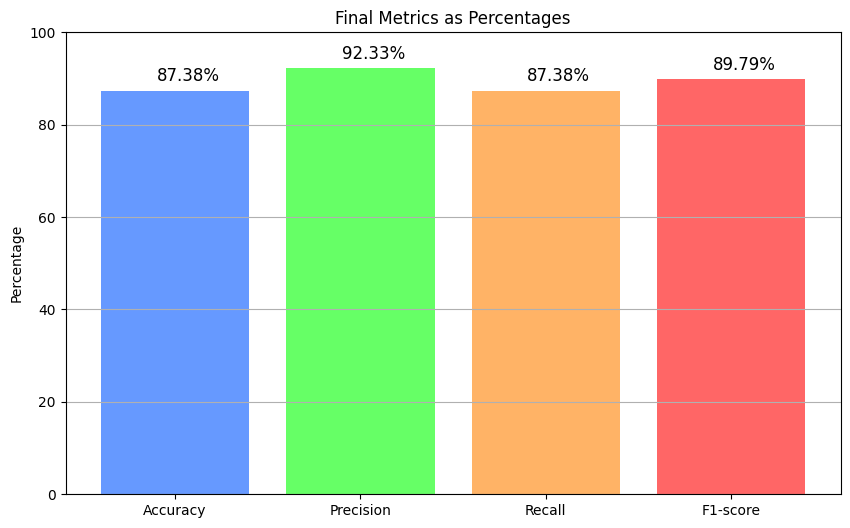

In [ ]:
# Assuming you have calculated these metrics for your model
#epochs = 10
accuracy = np.mean(attention_unet_4d_score)*100
precision = np.mean(attention_unet_4d_precision)*100
recall = np.mean(attention_unet_4d_recall)*100
f1_score = attention_unet_4d_f1_score*100
# List of metrics
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score']

# Corresponding values for each metric
values = [accuracy, precision, recall, f1_score]

plt.figure(figsize=(10, 6))

# Define lighter shades of colors
light_blue = (0.4, 0.6, 1.0)  # Light blue
light_green = (0.4, 1.0, 0.4)  # Light green
light_orange = (1.0, 0.7, 0.4)  # Light orange
light_red = (1.0, 0.4, 0.4)  # Light red

# Create bar plot with light colors
bars = plt.bar(metrics, values, color=[light_blue, light_green, light_orange, light_red])

plt.title('Final Metrics as Percentages')
plt.ylabel('Percentage')
plt.ylim(0, 100)  # Set the y-axis range to 0-100%
plt.grid(axis='y')

for bar, value in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width() / 2 - 0.1, value + 2, f'{value:.2f}%', fontsize=12, color='black')

plt.show()

In [ ]:
import cv2

In [ ]:
n=1

In [ ]:
mask=test_masks2[1]
main_image=test_images2[1]
pred = attention_unet_4d.predict(test_images2[1])

1/1 [==============================] - 0s 187ms/step


In [ ]:
prediction=pred

# Assuming 'mask' is your image with shape (1, 512, 512, 1)
prediction = np.squeeze(prediction, axis=0)  # Remove the batch dimension
# Squeeze out the channel dimension if it's a grayscale image
if prediction.shape[-1] == 1:
    prediction = np.squeeze(prediction, axis=-1)

# Assuming 'prediction' is now your final predicted image
# Rescale the image back to the original range if needed
prediction_rescaled = prediction * 255.0

# Convert the image to uint8 format
prediction_rescaled = prediction_rescaled.astype('uint8')

# If the image has only one channel, duplicate it to create a 3-channel image
if len(prediction_rescaled.shape) == 2:
    prediction_rescaled = cv2.cvtColor(prediction_rescaled, cv2.COLOR_GRAY2RGB)

# Save the image as TIFF
cv2.imwrite('predicted_image_1.tiff', prediction_rescaled)

True

In [ ]:
# Assuming 'mask' is your image with shape (1, 512, 512, 1)
mask = np.squeeze(mask, axis=0)  # Remove the batch dimension

# Squeeze out the channel dimension if it's a grayscale image
if mask.shape[-1] == 1:
    mask = np.squeeze(mask, axis=-1)

# Assuming 'mask' is now your final image
# Rescale the image back to the original range if needed
# Here's just an example, you might need to adapt it to your specific case
mask_rescaled = mask * 255.0

# Convert the image to uint8 format
mask_rescaled = mask_rescaled.astype('uint8')

# Save the image as TIFF
cv2.imwrite('mask_image_1.tiff', mask_rescaled)

True

In [ ]:
original=main_image

# Assuming 'original' is your image with shape (1, 512, 512, 1)
original = np.squeeze(original, axis=0)  # Remove the batch dimension

# Squeeze out the channel dimension if it's a grayscale image
if original.shape[-1] == 1:
    original = np.squeeze(original, axis=-1)

# Assuming 'original' is now your final image
# Rescale the image back to the original range if needed
# Here's just an example, you might need to adapt it to your specific case
original_rescaled = original * 255.0

# Convert the image to uint8 format
original_rescaled = original_rescaled.astype('uint8')

# Save the image as TIFF
cv2.imwrite('original_image_1.tiff', original_rescaled)

True

In [ ]:
# Assuming you have already imported necessary libraries and defined your ResUNet model (R_4band)

predictions = []

# Iterate over each preprocessed test image
for i in range(len(test_images2)):
    # Make prediction using the model
    prediction = attention_unet_4d.predict(test_images2[i])

    # Append the prediction to the list of predictions
    predictions.append(prediction)

# Now, 'predictions' will contain the predictions for each test image

1/1 [==============================] - 0s 181ms/step


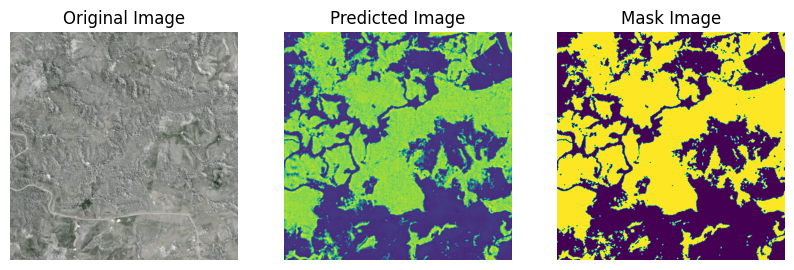

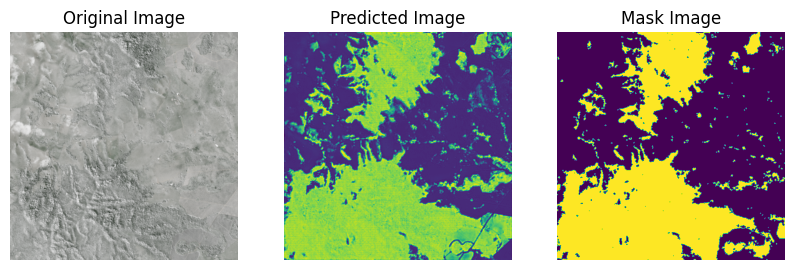

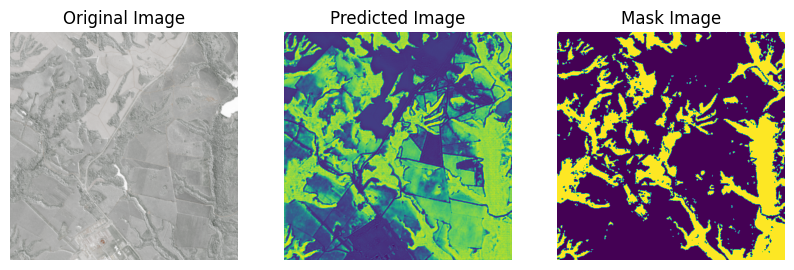

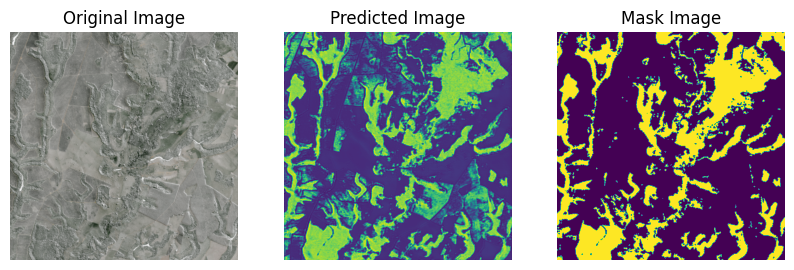

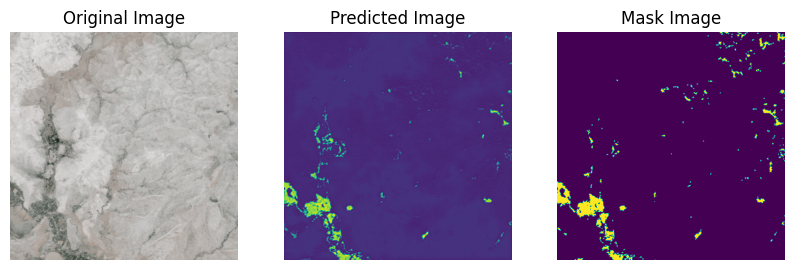

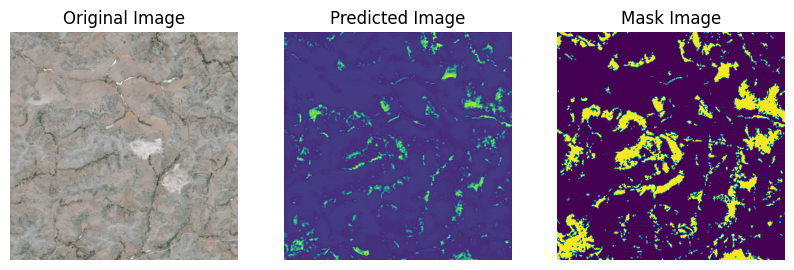

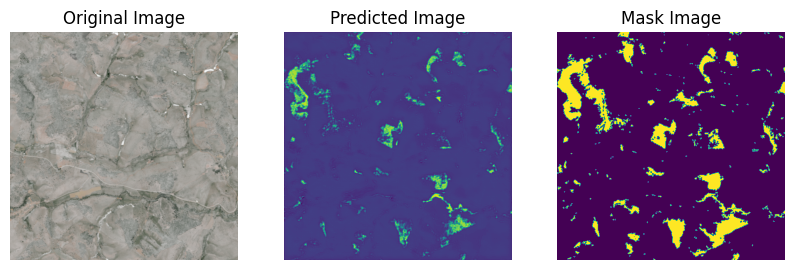

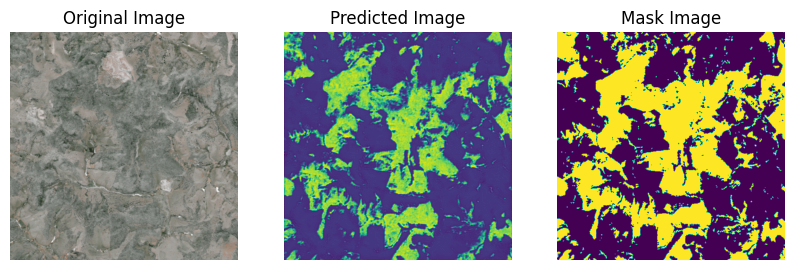

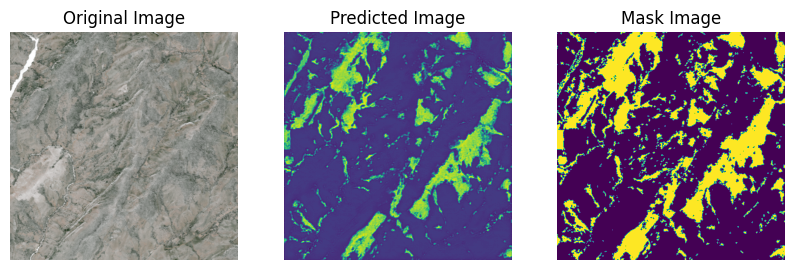

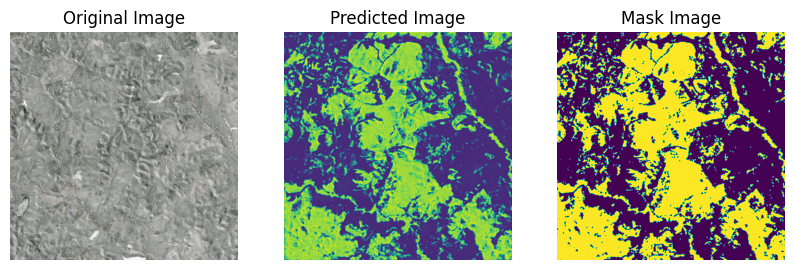

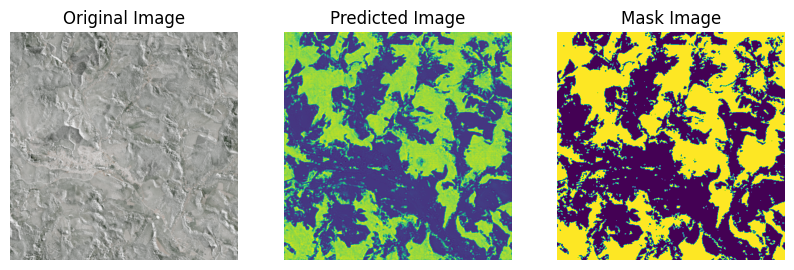

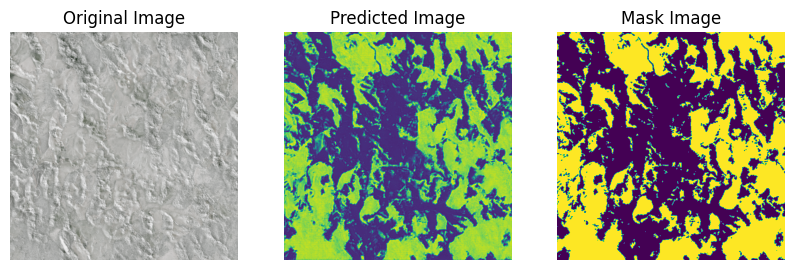

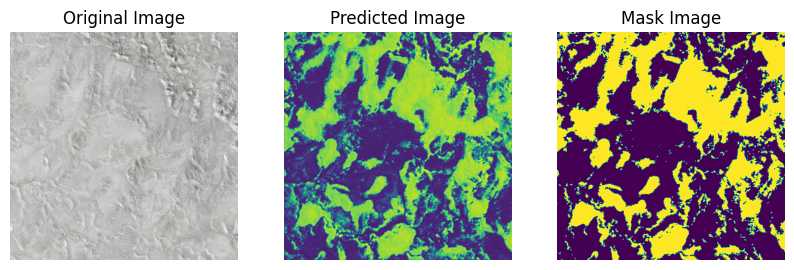

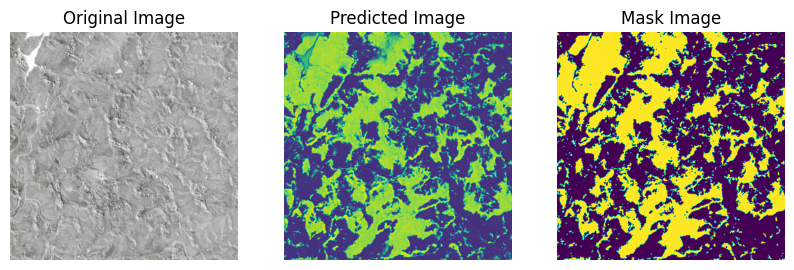

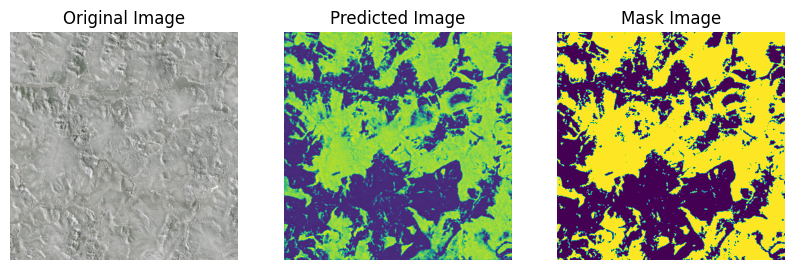

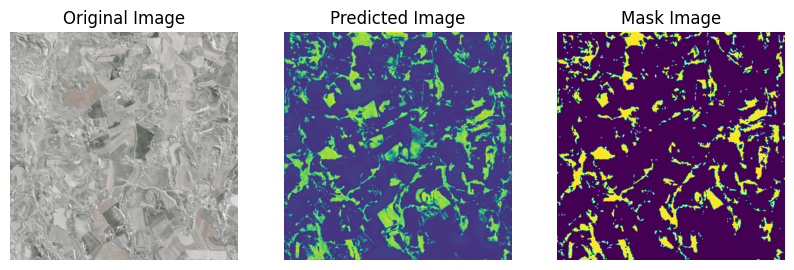

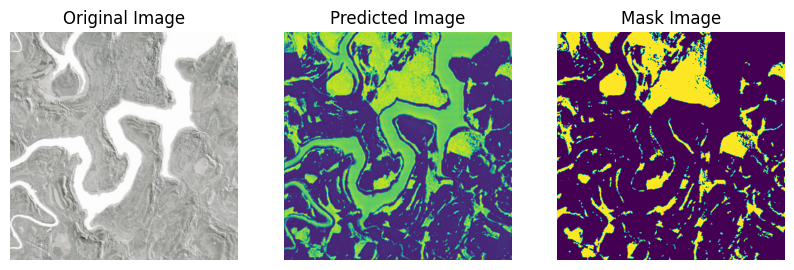

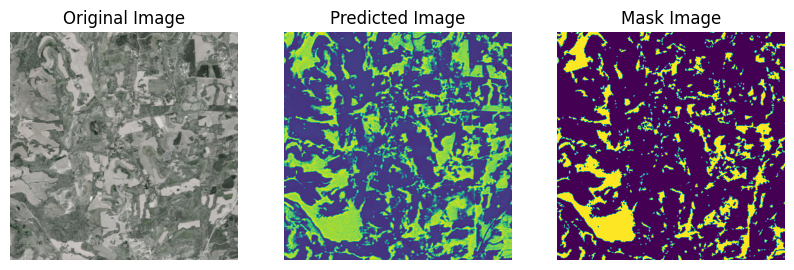

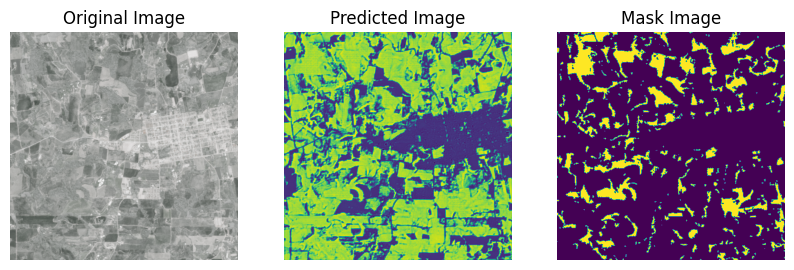

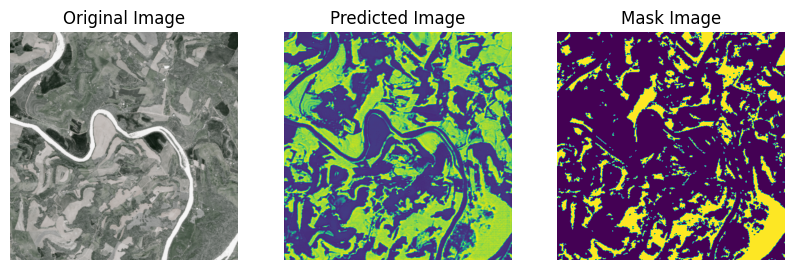

In [ ]:
import matplotlib.pyplot as plt

# Assuming 'predictions' contains the predictions for each test image
# and 'test_images' contains the preprocessed test images
output_folder = 'E:/Atlantic_Codes/atlantic_predictions_4d_no_threshold_BatchNorm/'

# Plot the original and predicted images
for i in range(len(test_images2)):
    plt.figure(figsize=(10, 5))

    # Original Image
    plt.subplot(1, 3, 1)
    plt.title('Original Image')
    plt.imshow(test_images2[i][0])  # Assuming your test_images are of shape (1, 512, 512, 3)
    plt.axis('off')

    # Predicted Image
    plt.subplot(1, 3, 2)
    plt.title('Predicted Image')
    plt.imshow(predictions[i][0])  # Assuming your predictions are of shape (1, 512, 512, num_classes)
    plt.axis('off')


    # Predicted Image
    plt.subplot(1, 3, 3)
    plt.title('Mask Image')
    plt.imshow(test_masks2[i][0])  # Assuming your predictions are of shape (1, 512, 512, num_classes)
    plt.axis('off')

    plt.show()

Saving to a folder

In [ ]:
import os
import numpy as np
import tifffile

# Assuming 'predictions' is a list of prediction arrays
for i, prediction in enumerate(predictions):
    # Create a filename for the TIFF file
    filename = os.path.join('E:/Atlantic_Codes/atlantic_predictions_4d_no_threshold_BatchNorm/', f'prediction_{i}.tiff')

    # Convert prediction array to uint8 (adjust as needed)
    prediction_uint8 = (prediction * 255).astype(np.uint8)

    # Save the prediction as a TIFF file
    tifffile.imwrite(filename, prediction_uint8)

    print(f"Saved prediction {i} to {filename}")

Saved prediction 0 to E:/Atlantic_Codes/atlantic_predictions_4d_no_threshold_BatchNorm/prediction_0.tiff
Saved prediction 1 to E:/Atlantic_Codes/atlantic_predictions_4d_no_threshold_BatchNorm/prediction_1.tiff
Saved prediction 2 to E:/Atlantic_Codes/atlantic_predictions_4d_no_threshold_BatchNorm/prediction_2.tiff
Saved prediction 3 to E:/Atlantic_Codes/atlantic_predictions_4d_no_threshold_BatchNorm/prediction_3.tiff
Saved prediction 4 to E:/Atlantic_Codes/atlantic_predictions_4d_no_threshold_BatchNorm/prediction_4.tiff
Saved prediction 5 to E:/Atlantic_Codes/atlantic_predictions_4d_no_threshold_BatchNorm/prediction_5.tiff
Saved prediction 6 to E:/Atlantic_Codes/atlantic_predictions_4d_no_threshold_BatchNorm/prediction_6.tiff
Saved prediction 7 to E:/Atlantic_Codes/atlantic_predictions_4d_no_threshold_BatchNorm/prediction_7.tiff
Saved prediction 8 to E:/Atlantic_Codes/atlantic_predictions_4d_no_threshold_BatchNorm/prediction_8.tiff
Saved prediction 9 to E:/Atlantic_Codes/atlantic_predic

In [ ]:
save_dir = "E:/Atlantic_Codes/atlantic_predicted_with_threshold_BatchNorm/"

In [ ]:
import os
import numpy as np
from PIL import Image


# Create the directory if it doesn't exist
os.makedirs(save_dir, exist_ok=True)

# Threshold value
threshold = 127
# Assuming 'predictions' contains the predictions for each test image
# and 'test_images' contains the preprocessed test images

for i in range(len(predictions)):
    # Extract the predicted image array and scale it to the range [0, 255]
    predicted_image_array = (predictions[i][0] * 255).astype(np.uint8)

    # Apply binary thresholding
    binary_predicted_image_array = np.where(predicted_image_array > threshold, 255, 0).astype(np.uint8)

    # Convert the binary image array to a PIL image
    predicted_image = Image.fromarray(binary_predicted_image_array.squeeze(), mode='L')

    # Save the predicted image in the specified directory
    predicted_image.save(os.path.join(save_dir, f'predicted_image_{i}.png'))

# The predicted images will be saved in the directory specified by 'save_dir'

In [ ]:
save_dir = "E:/Atlantic_Codes/original_images/"

In [ ]:
import os
import numpy as np
from tifffile import imsave

# Create the directory if it doesn't exist
os.makedirs(save_dir, exist_ok=True)

# Save each band of the original images as TIFF files
for i, image_array in enumerate(test_images2):
    # Assuming the image_array has shape (1, height, width, 4) with RGBA channels
    for band_idx, band_name in enumerate(['red', 'green', 'blue', 'nir']):
        # Extract the band
        band = image_array[..., band_idx]

        # Save the band as a TIFF file in the specified directory
        save_path = os.path.join(save_dir, f'original_image_{i}_{band_name}.tiff')
        imsave(save_path, band.squeeze())

# The bands of the original images will be saved as TIFF files in the directory specified by 'save_dir'

C:\Users\T20101537\AppData\Local\Temp\ipykernel_19816\2467288970.py:17: DeprecationWarning: <tifffile.imsave> is deprecated. Use tifffile.imwrite
  imsave(save_path, band.squeeze())


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm  # optional, for progress bar

# ----------------------------
# Define IoU function
# ----------------------------
def iou_metric(y_true, y_pred, threshold=0.5):
    """
    Calculate IoU between ground truth and predicted masks.
    Args:
        y_true: Ground truth mask (numpy array)
        y_pred: Predicted mask (numpy array)
        threshold: Threshold to binarize predictions
    Returns:
        IoU score (float)
    """
    y_pred_bin = (y_pred > threshold).astype(np.uint8)
    y_true_bin = (y_true > 0.5).astype(np.uint8)

    intersection = np.logical_and(y_true_bin, y_pred_bin).sum()
    union = np.logical_or(y_true_bin, y_pred_bin).sum()

    if union == 0:
        return 1.0 if intersection == 0 else 0.0
    return intersection / union

# ----------------------------
# Evaluate on validation set
# ----------------------------
ious = []

for i in tqdm(range(len(validation_images2)), desc="Evaluating IoU"):
    # Get prediction
    image = np.expand_dims(validation_images2[i], axis=0)
    pred_mask = attention_unet_4d.predict(image)[0]

    # Get ground truth
    true_mask = validation_masks2[i]

    # Compute IoU
    iou = iou_metric(true_mask, pred_mask)
    ious.append(iou)

# ----------------------------
# Report results
# ----------------------------
mean_iou = np.mean(ious)
std_iou = np.std(ious)

print("\n--- IoU Evaluation ---")
print(f"Mean IoU: {mean_iou:.4f}")
print(f"Standard Deviation: {std_iou:.4f}")

# ----------------------------
# Optional: plot IoU histogram
# ----------------------------
plt.figure(figsize=(8, 5))
plt.hist(ious, bins=20, color='skyblue', edgecolor='black')
plt.title('IoU Distribution on Validation Set')
plt.xlabel('IoU Score')
plt.ylabel('Number of Images')
plt.grid(axis='y')
plt.show()

NameError: name 'validation_images2' is not defined